**Q6. Use Simple Kmeans, DBScan, Hierachical clustering algorithms for clustering.**<br>
**Compare the performance of clusters by changing the parameters involved in the algorithms.**



In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn import metrics

In [2]:
iris = load_iris()

In [3]:
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['Class'] = iris.target

In [4]:
df_iris.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0


In [9]:
df_iris.shape

(150, 5)

In [10]:
df_iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [11]:
df_iris.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Class
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [14]:
scaler = StandardScaler() 
scaled_X = scaler.fit_transform(df_iris.iloc[:, :-1])

In [16]:
df_iris_scaled = pd.DataFrame(scaled_X, columns = list(df_iris.columns)[:-1])

In [17]:
df_iris_scaled["class"] = df_iris["Class"]

In [18]:
df_iris_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,-0.900681,1.019004,-1.340227,-1.315444,0
1,-1.143017,-0.131979,-1.340227,-1.315444,0
2,-1.385353,0.328414,-1.397064,-1.315444,0
3,-1.506521,0.098217,-1.283389,-1.315444,0
4,-1.021849,1.249201,-1.340227,-1.315444,0


In [21]:
df_iris_scaled.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
count,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02,150.000000
mean,-1.468455e-15,-1.823726e-15,-1.610564e-15,-9.473903e-16,1.000000
std,1.003350e+00,1.003350e+00,1.003350e+00,1.003350e+00,0.819232
min,-1.870024e+00,-2.433947e+00,-1.567576e+00,-1.447076e+00,0.000000
25%,-9.006812e-01,-5.923730e-01,-1.226552e+00,-1.183812e+00,0.000000
50%,-5.250608e-02,-1.319795e-01,3.364776e-01,1.325097e-01,1.000000
75%,6.745011e-01,5.586108e-01,7.627583e-01,7.906707e-01,2.000000
max,2.492019e+00,3.090775e+00,1.785832e+00,1.712096e+00,2.000000


In [22]:
import matplotlib.pyplot as plt

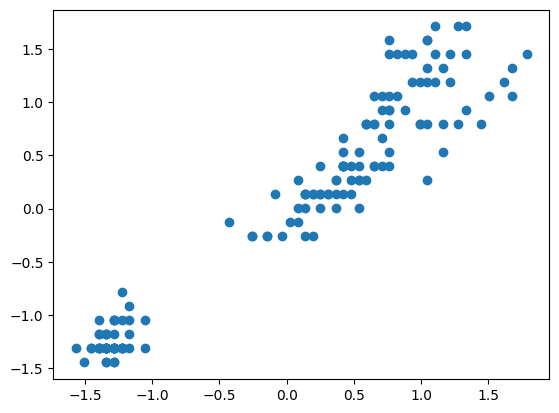

In [23]:
plt.scatter(df_iris_scaled["petal length (cm)"], df_iris_scaled["petal width (cm)"])

In [25]:
X= df_iris_scaled.iloc[:, :-1]
Y= df_iris_scaled["class"]

In [26]:
X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444
...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832
146,0.553333,-1.282963,0.705921,0.922303
147,0.795669,-0.131979,0.819596,1.053935
148,0.432165,0.788808,0.933271,1.448832


In [27]:
Y

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: class, Length: 150, dtype: int64

**KMeans Clustering**

In [28]:
from sklearn.cluster import KMeans

In [30]:
kmeans = KMeans(n_clusters = 3, random_state = 1 , n_init = 'auto')

In [32]:
kmeans.fit(X)

KMeans(n_clusters=3, random_state=1)

In [33]:
center = kmeans.cluster_centers_

In [34]:
identified_clusters = kmeans.fit_predict(X)
identified_clusters

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 0, 2, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2], dtype=int32)

In [35]:
temp1= X[identified_clusters == 0]
temp2= X[identified_clusters == 1]
temp3= X[identified_clusters == 2]

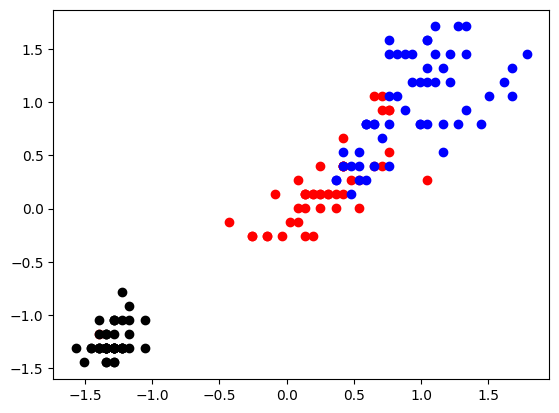

In [36]:
#Plotting the results
plt.scatter(temp1.iloc[:, 2], temp1.iloc[:,3], color = 'red')
plt.scatter(temp2.iloc[:, 2], temp2.iloc[:,3], color = 'black')
plt.scatter(temp3.iloc[:, 2], temp3.iloc[:,3], color = 'blue')
plt.show()

**DBScan**

In [37]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [38]:
neigh= NearestNeighbors(n_neighbors=2)

In [39]:
nbrs=neigh.fit(X)

In [40]:
distances, indices = nbrs.kneighbors(X)

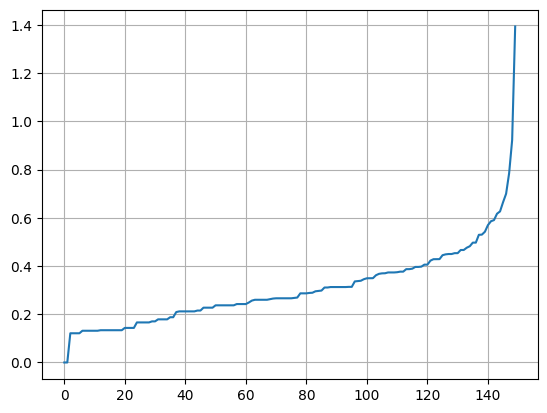

In [41]:
distances = np.sort(distances, axis=0)
distances= distances[:, 1]
plt.plot(distances)
plt.grid()
plt.show()

In [42]:
dbscan=DBSCAN(eps=0.6,min_samples=3)
dbscan.fit(X)

DBSCAN(eps=0.6, min_samples=3)

In [43]:
identified_clusters_db= dbscan.fit_predict(X)
identified_clusters_db

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1,  2,  1,  1, -1,  1, -1,  1,  1,  1,  1,  1,
        3,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  3,  1,  1,  1,  1,  1,  2,  1,  1,  1,  1,  2,  1,  1,  1,
        1,  1,  1,  1, -1,  1, -1, -1,  1,  1,  1,  1,  1,  1,  1, -1, -1,
        3,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [50]:
unique_clusters = np.unique(identified_clusters_db)

In [51]:
li = []
for i in range(len(unique_clusters)):
    li.append(X[identified_clusters_db == unique_clusters[i]])

In [52]:
import random
no_of_colors = len(li)
color= ["#"+''.join([random.choice('0123456789ABCDEF') for i in range(6)]) for j in range(no_of_colors)] 

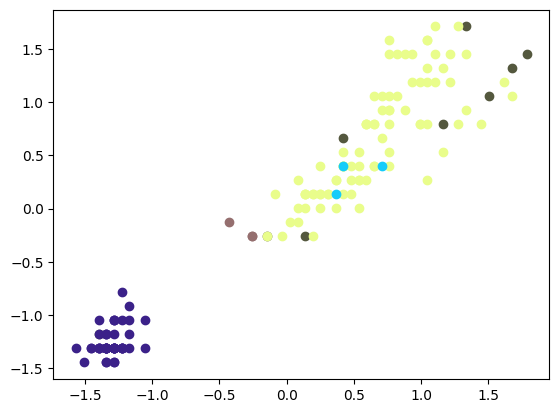

In [54]:
#Plotting the results
for i in range(len(li)):
    plt.scatter(li[i].iloc[:,2], li[i].iloc[:, 3], color = color[i])
plt.show()

**Hierarchical Clustering**

In [55]:
from sklearn.cluster import AgglomerativeClustering

In [56]:
hier_clus = AgglomerativeClustering(n_clusters =3)
hier_clus.fit(X)

AgglomerativeClustering(n_clusters=3)

In [58]:
identified_clusters_hc = hier_clus.fit_predict(X)
identified_clusters_hc

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 0, 2, 0,
       2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2,
       2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

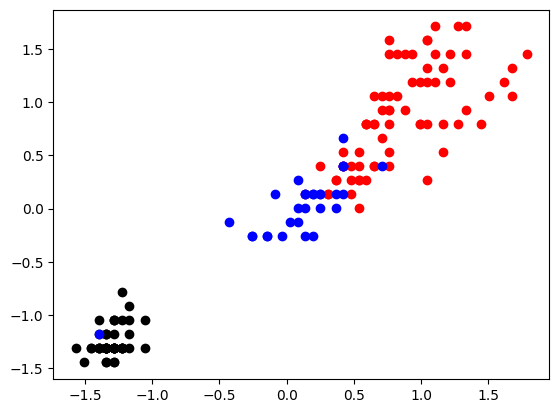

In [59]:
temp1= X[identified_clusters_hc ==0]
temp2= X[identified_clusters_hc ==1]
temp3= X[identified_clusters_hc ==2]

#Plotting the results

plt.scatter(temp1.iloc[:, 2], temp1.iloc[:,3], color = 'red')
plt.scatter(temp2.iloc[:, 2], temp2.iloc[:,3], color = 'black')
plt.scatter(temp3.iloc[:, 2], temp3.iloc[:,3], color = 'blue')
plt.show()


In [60]:
from scipy.cluster import hierarchy

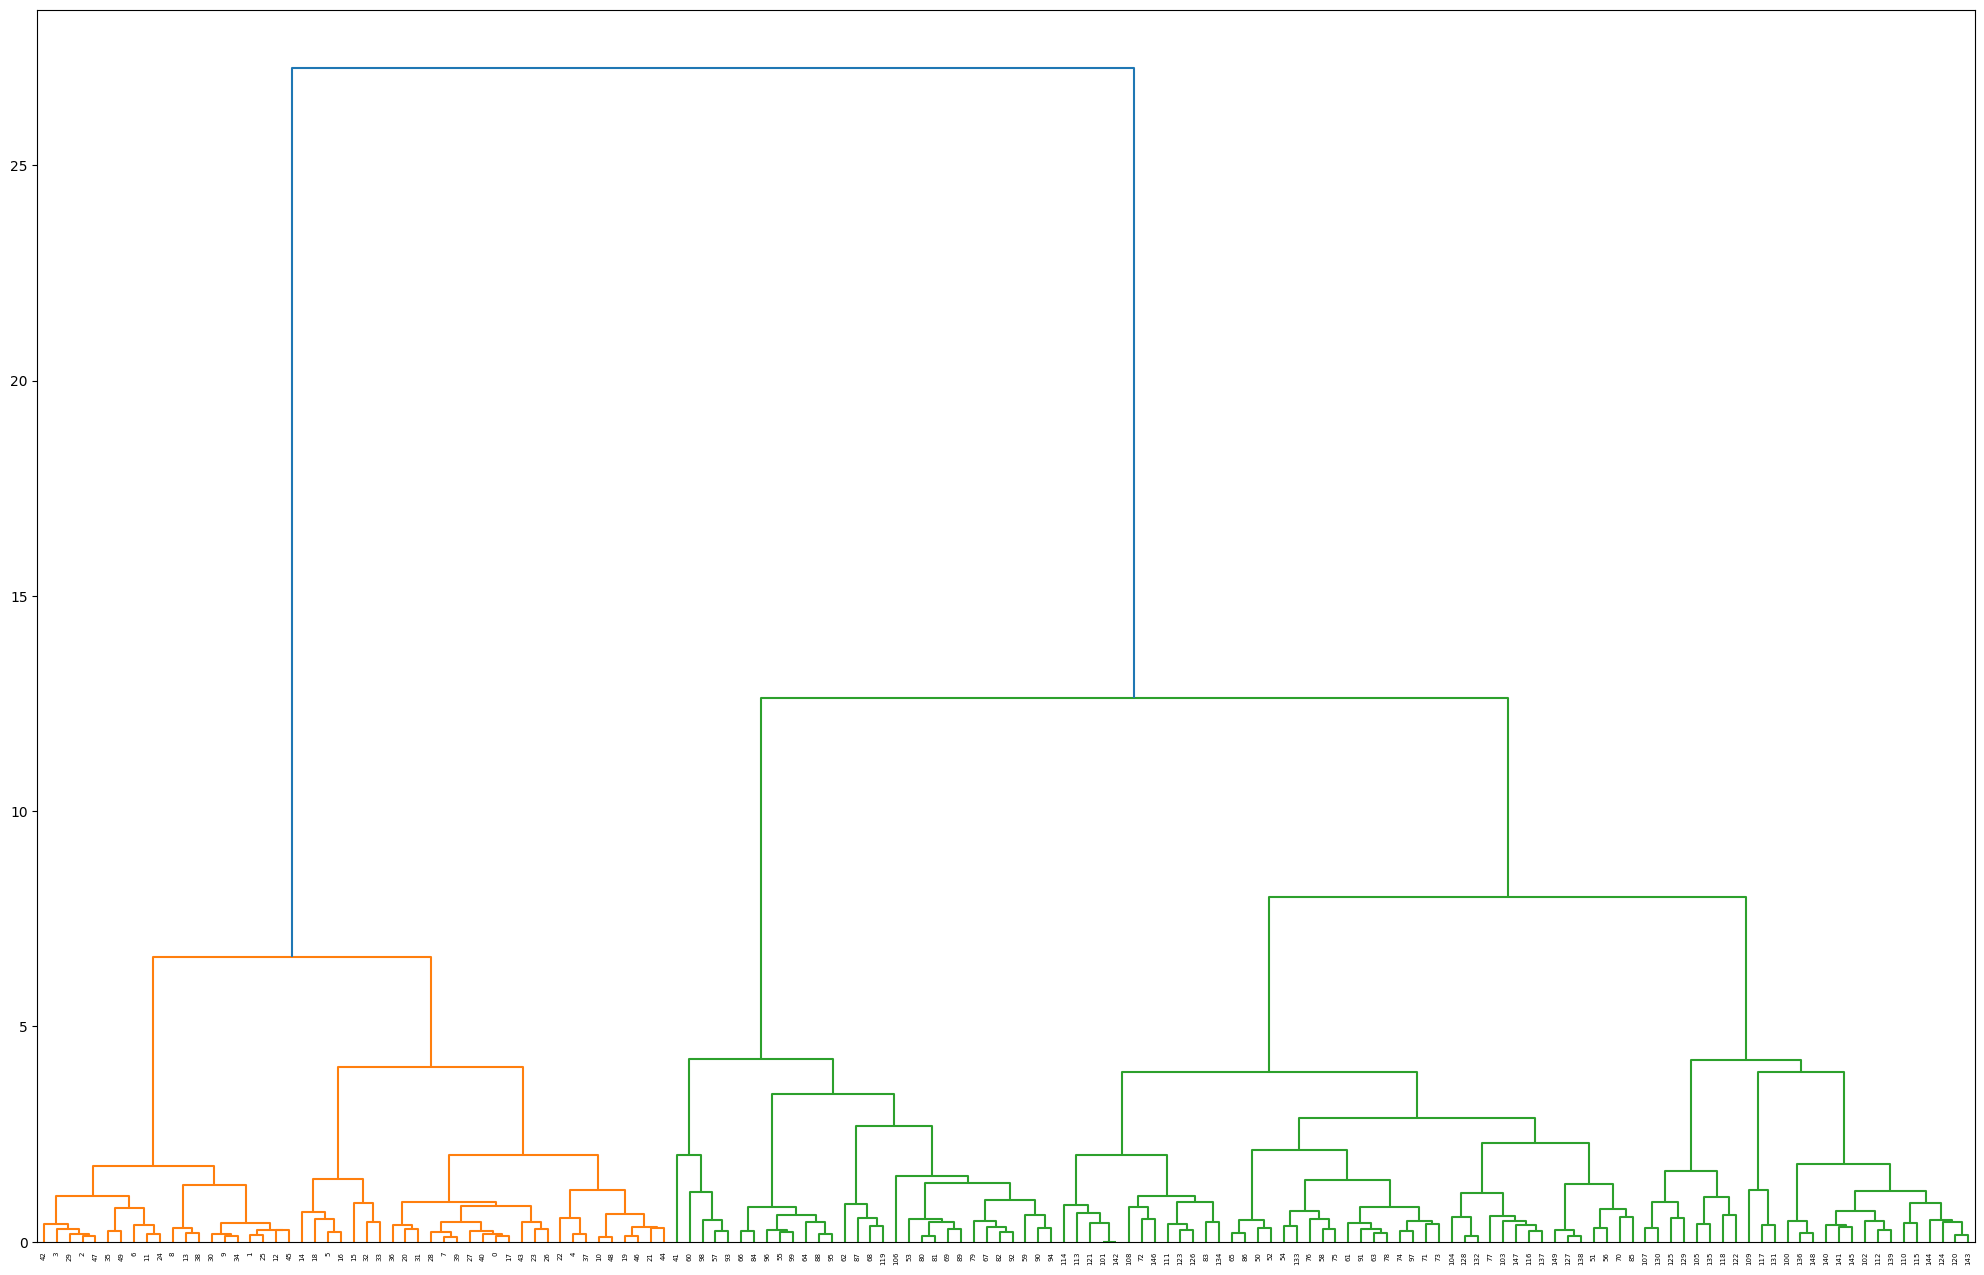

In [69]:
clusters = hierarchy.linkage(X, method="ward")
plt.figure(figsize=(25,16))
dendrogram= hierarchy.dendrogram(clusters)